# Validate against onshore buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Raw buoy exports under `inputs/Observations/raw/` — converted to the processed
   `hs`/`dir` schema in section 2 below (cached under `inputs/Observations/processed/`).

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically — this case's buoys are all
Rijkswaterstaat Waterinfo/DDL exports (`Hm0`/`Th0`/`Tm-10`), which only give
usable `hs`/`dir` (see `utils/rijkswaterstaat.py`: `Tm-10` is a
spectral mean period, not the peak period `tp` the metamodel predicts, so it's
dropped rather than mislabeled — `tp`/`spr` are simply not scored against
buoys here).

This case has a single (nearshore) buoy network, so the separate
`10a_Validate_Offshore_Buoys.ipynb` template was dropped — this notebook
covers all 9 configured buoys.

In [2]:
import time

import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils import validation as val
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import rijkswaterstaat as rws

## Configuration

All 9 buoys from the observations GeoJSON (`instrument_id` keys) — this case has one
buoy network. SnapWave site labels are `buoy_{instrument_id}`. Raw files come from
Rijkswaterstaat Waterinfo/DDL; section 2 converts them to the processed schema.

In [3]:
period = slice("2010", "2015")  # matches the 09/reconstruction cache span
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99

# instrument_id values from the observations GeoJSON (notebook 03) — all 9
# Rijkswaterstaat stations configured for this case.
buoy_instruments = [
    "AmelanderZeegat_1_1",
    "AmelanderZeegat_1_2",
    "EierlandseGat",
    "EurogeulE13",
    "IJmuidenMunitiestort_1",
    "PettenMeetraai01",
    "StortemelkWest",
    "WestereemsWest",
    "ZandmoterBoeiNoord",
]
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]

# Raw Waterinfo/DDL export per instrument_id — converted to the processed
# hs/dir schema in section 2 below.
raw_buoy_files = {
    "AmelanderZeegat_1_1": "inputs/Observations/raw/amelanderzeegat.1.1-Amelander_zeegat_1_1.nc",
    "AmelanderZeegat_1_2": "inputs/Observations/raw/amelanderzeegat.1.2-Amelander_zeegat_1_2.nc",
    "EierlandseGat": "inputs/Observations/raw/eierlandsegat-Eierlandse_Gat.nc",
    "EurogeulE13": "inputs/Observations/raw/eurogeul.e13-Eurogeul_E13.nc",
    "IJmuidenMunitiestort_1": "inputs/Observations/raw/ijmuiden.munitiestort.1-IJmuiden_munitiestort_1.nc",
    "PettenMeetraai01": "inputs/Observations/raw/petten.meetraai1-Petten_meetraai_01.nc",
    "StortemelkWest": "inputs/Observations/raw/stortemelk.west-Stortemelk_west.nc",
    "WestereemsWest": "inputs/Observations/raw/westereems.west-Westereems_west.nc",
    "ZandmoterBoeiNoord": "inputs/Observations/raw/zandmoter.boei.noord-Zandmoter_boei_noord.nc",
}

requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"])
    / f"Dynamic_Cases_{offshore_name}_2010-2015.nc"
)

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
period         : slice('2010', '2015', None)
mda_n          : 450
sites          : ['buoy_AmelanderZeegat_1_1', 'buoy_AmelanderZeegat_1_2', 'buoy_EierlandseGat', 'buoy_EurogeulE13', 'buoy_IJmuidenMunitiestort_1', 'buoy_PettenMeetraai01', 'buoy_StortemelkWest', 'buoy_WestereemsWest', 'buoy_ZandmoterBoeiNoord']
requested vars : ['hs', 'tp', 'dir', 'spr']
dynamic path   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2010-2015.nc
dynamic exists : True


## 1 · Check models

In [4]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Process buoy observations

**2a.** Convert each raw Rijkswaterstaat export to the processed `hs`/`dir` schema
(cm → m, quality-code + physical-range filtering — see
`utils/rijkswaterstaat.py`) and cache under
`inputs/Observations/processed/`.

**2b.** Load each processed file, slice to `period`, and build a validation dataset
on `(time, sites)` with CF-style attributes. Site metadata (lon/lat/depth) comes
from the observations GeoJSON.

In [5]:
processed_dir = resolve("inputs/Observations/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

# Processed observation NetCDF per SnapWave site id — built once here, then
# reused on later runs (delete the file to force reprocessing a buoy).
buoy_raw_files: dict[str, str] = {}
for instrument_id, raw_path in raw_buoy_files.items():
    site_id = obs.snapwave_site_id(instrument_id)
    out_path = processed_dir / f"{instrument_id}.nc"
    if not out_path.is_file():
        rws.process_raw_buoy(raw_path).to_netcdf(out_path)
    buoy_raw_files[site_id] = out_path
    with xr.open_dataset(out_path) as check:
        n_valid = int(check["hs"].sel(time=period).notnull().sum())
    print(f"{site_id}: {n_valid} valid hs sample(s) in {period} -> {out_path.name}")

buoy_AmelanderZeegat_1_1: 159852 valid hs sample(s) in slice('2010', '2015', None) -> AmelanderZeegat_1_1.nc


buoy_AmelanderZeegat_1_2: 156840 valid hs sample(s) in slice('2010', '2015', None) -> AmelanderZeegat_1_2.nc
buoy_EierlandseGat: 277029 valid hs sample(s) in slice('2010', '2015', None) -> EierlandseGat.nc


buoy_EurogeulE13: 266848 valid hs sample(s) in slice('2010', '2015', None) -> EurogeulE13.nc
buoy_IJmuidenMunitiestort_1: 285968 valid hs sample(s) in slice('2010', '2015', None) -> IJmuidenMunitiestort_1.nc
buoy_PettenMeetraai01: 52033 valid hs sample(s) in slice('2010', '2015', None) -> PettenMeetraai01.nc
buoy_StortemelkWest: 279682 valid hs sample(s) in slice('2010', '2015', None) -> StortemelkWest.nc
buoy_WestereemsWest: 278268 valid hs sample(s) in slice('2010', '2015', None) -> WestereemsWest.nc
buoy_ZandmoterBoeiNoord: 1742 valid hs sample(s) in slice('2010', '2015', None) -> ZandmoterBoeiNoord.nc


In [6]:
# CF-style attributes for validation plots
_BUOY_VAR_ATTRS = {
    "hs": {"standard_name": "sea_surface_wave_significant_height", "units": "m"},
    "tp": {"standard_name": "sea_surface_wave_period", "units": "s"},
    "dir": {"standard_name": "sea_surface_wave_from_direction", "units": "degree"},
    "spr": {
        "standard_name": "sea_surface_wave_directional_spread",
        "units": "degree",
    },
}

chunks: list[xr.Dataset] = []
for site_id in sites:
    raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)

    if "Efth" in raw or "efth" in raw:
        spec_name = "Efth" if "Efth" in raw else "efth"
        stats = raw[spec_name].spec.stats(["hs", "tp", "dm", "dspr"]).load()
        site_ds = stats.rename({"dm": "dir", "dspr": "spr"})
    else:
        rename = {}
        if "dspr" in raw.data_vars and "spr" not in raw.data_vars:
            rename["dspr"] = "spr"
        if rename:
            raw = raw.rename(rename)
        vars_out = {}
        for name in requested_variables:
            if name in raw.data_vars:
                vars_out[name] = raw[name]
            elif name == "dir" and "dm" in raw.data_vars:
                vars_out["dir"] = raw["dm"]
        if "hs" not in vars_out:
            raise ValueError(f"{site_id}: processed buoy file must contain hs or Efth")
        site_ds = xr.Dataset(vars_out)

    site_ds = site_ds.expand_dims(sites=[site_id]).transpose("time", "sites")
    for var, attrs in _BUOY_VAR_ATTRS.items():
        if var in site_ds:
            site_ds[var].attrs.update(attrs)
    chunks.append(obs.attach_buoy_site_meta(site_ds, site_id))

buoy = xr.concat(chunks, dim="sites") if len(chunks) > 1 else chunks[0]
buoy

<xarray.Dataset> Size: 48MB
Dimensions:         (time: 315504, sites: 9)
Coordinates:
  * time            (time) datetime64[ns] 3MB 2010-01-01 ... 2015-12-31T23:50:00
  * sites           (sites) object 72B 'buoy_AmelanderZeegat_1_1' ... 'buoy_Z...
    site_source     (sites) <U4 144B 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label      (sites) <U22 792B 'AmelanderZeegat_1_1' ... 'ZandmoterBoe...
    site_longitude  (sites) float64 72B 5.481 5.484 4.66 ... 4.996 6.367 4.158
    site_latitude   (sites) float64 72B 53.51 53.51 53.28 ... 53.32 53.62 52.05
    site_depth      (sites) float64 72B nan nan nan nan nan nan nan nan nan
Data variables:
    hs              (time, sites) float64 23MB 2.1 2.03 1.89 ... 1.22 nan nan
    dir             (time, sites) float64 23MB 33.0 28.0 33.0 ... 246.0 nan nan

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in the case JSON —
currently WHACS only).

In [7]:
timings: dict[str, float] = {}

t0 = time.perf_counter()
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,  # this notebook only ever scores bulk stats
    # (hs/tp/dir/spr) against buoys — never reads spectra. The case JSON
    # defaults save_spectra=true (for notebook 11), which needlessly
    # computes and caches a full (time, sites, freq, dir) array per batch
    # here (~1000x bigger than the bulk stats actually used below) — see
    # 09's cell 7 for the same fix and the memory-blowup story behind it.
)
timings["Bulk metamodel"] = time.perf_counter() - t0

t0 = time.perf_counter()
spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    save_spectra=False,
)
timings["Spectral metamodel"] = time.perf_counter() - t0
# Near-zero above means these sites/period were already cached from a
# previous run, not a fresh-reconstruction cost. Offshore hindcast below
# is a plain lookup, not a reconstruction, so it has no timing entry.

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Spectral metamodel": spectral,
    "Dynamic SnapWave": dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'dir']


## 4 · Metrics vs buoy

In [8]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
    pca_variance=pca_variance,
)

summary = val.metrics_summary(results)
summary

,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AmelanderZeegat_1_1,buoy,waves,hs,Hs,26691,0.322669,0.520645,0.673324,WHACS (closest goal),Buoy,WHACS (closest goal)
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AmelanderZeegat_1_1,buoy,waves,dir,Dir,26632,-1.906361,30.989626,0.735161,WHACS (closest goal),Buoy,WHACS (closest goal)
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AmelanderZeegat_1_2,buoy,waves,hs,Hs,26073,0.315282,0.524479,0.627357,WHACS (closest goal),Buoy,WHACS (closest goal)
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AmelanderZeegat_1_2,buoy,waves,dir,Dir,26007,-2.801865,34.235298,0.609541,WHACS (closest goal),Buoy,WHACS (closest goal)
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_EierlandseGat,buoy,waves,hs,Hs,46877,0.032476,0.246078,0.895514,WHACS (closest goal),Buoy,WHACS (closest goal)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_StortemelkWest,buoy,waves,dir,Dir,15772,2.626590,25.235103,0.649444,Dynamic SnapWave,Buoy,Dynamic SnapWave
68,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_WestereemsWest,buoy,waves,hs,Hs,15385,-0.048409,0.288390,0.777244,Dynamic SnapWave,Buoy,Dynamic SnapWave
69,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_WestereemsWest,buoy,waves,dir,Dir,15351,2.503169,29.602902,0.613986,Dynamic SnapWave,Buoy,Dynamic SnapWave
70,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_ZandmoterBoeiNoord,buoy,waves,hs,Hs,0,NaN,NaN,NaN,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 4b · Save summary

In [9]:
# `period` is a slice here (not a single string) — derive a clean,
# filesystem-safe label from it once; the summary PNG save cell reuses it.
period_label = period if isinstance(period, str) else f"{period.start}-{period.stop}"

summary_out = summary.copy()
summary_out.insert(0, "period", period_label)
summary_out.insert(1, "mda_candidate", mda_n)
summary_out.insert(2, "offshore_name", offshore_name)
summary_out["reconstruct_seconds"] = summary_out["model"].map(timings)

out_path = val.buoy_validation_path("onshore", period_label)
out_path.parent.mkdir(parents=True, exist_ok=True)
summary_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/onshore_summary_2010-2015.csv


## 5 · Scatter plots

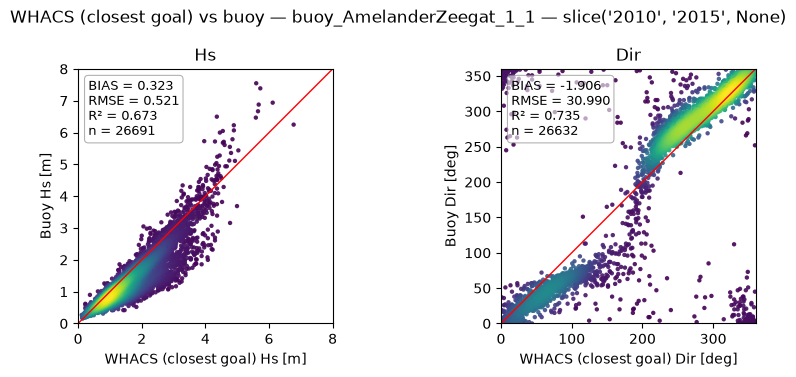

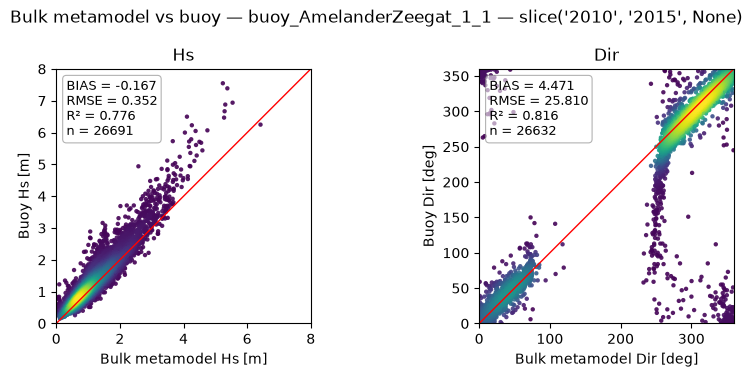

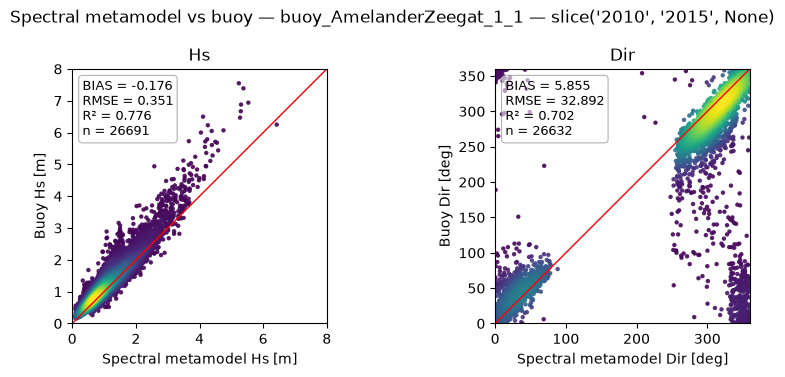

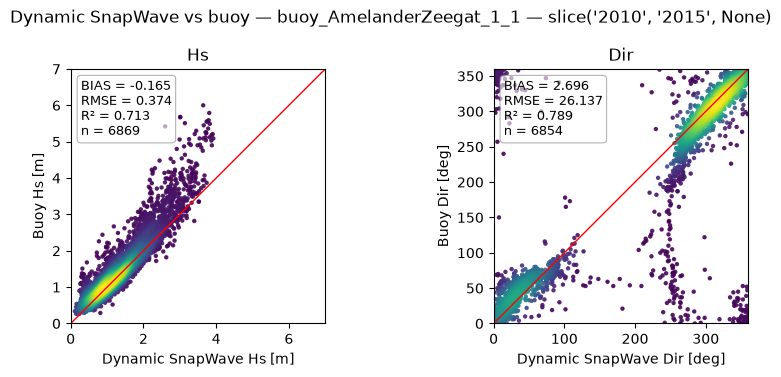

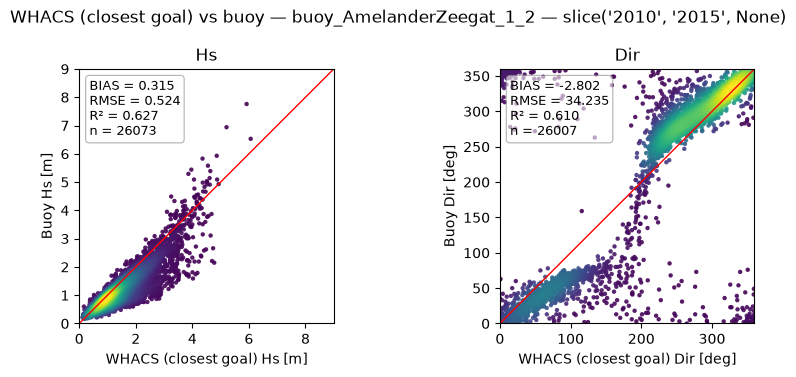

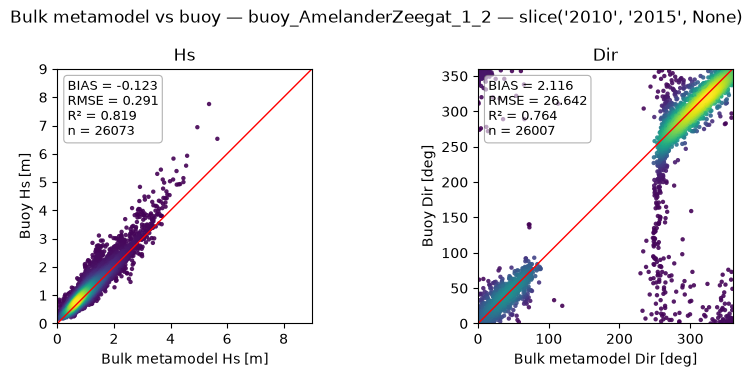

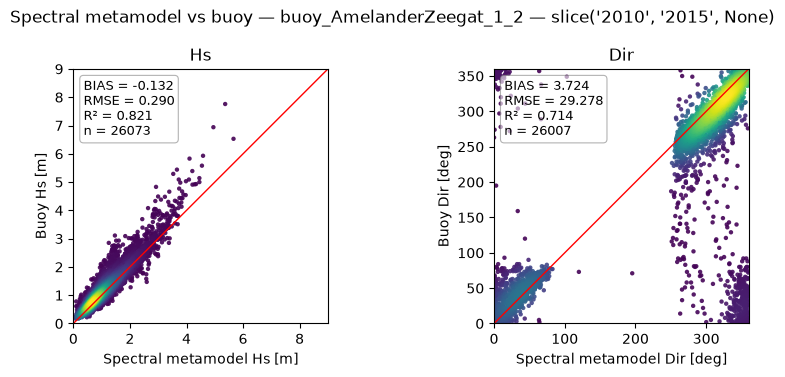

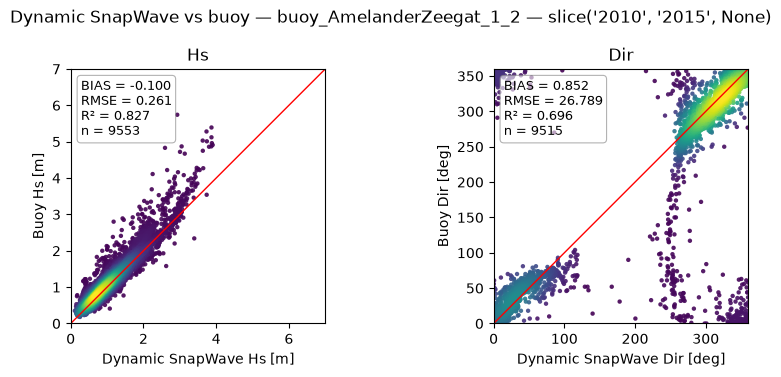

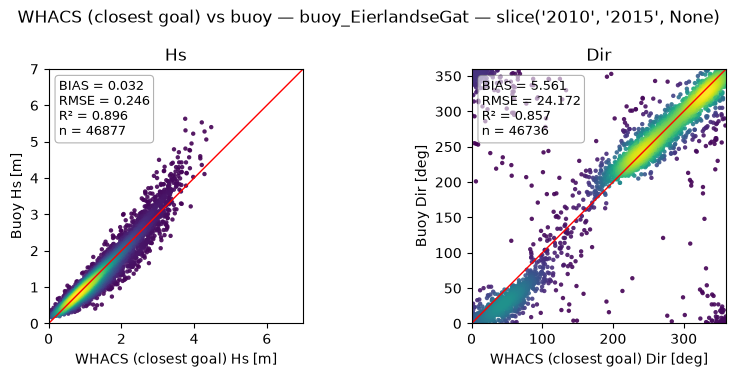

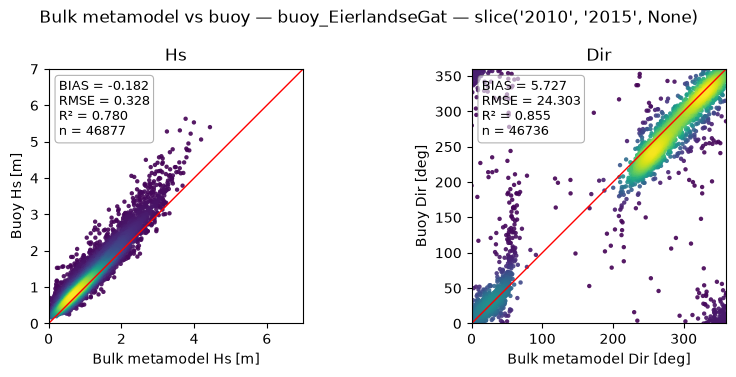

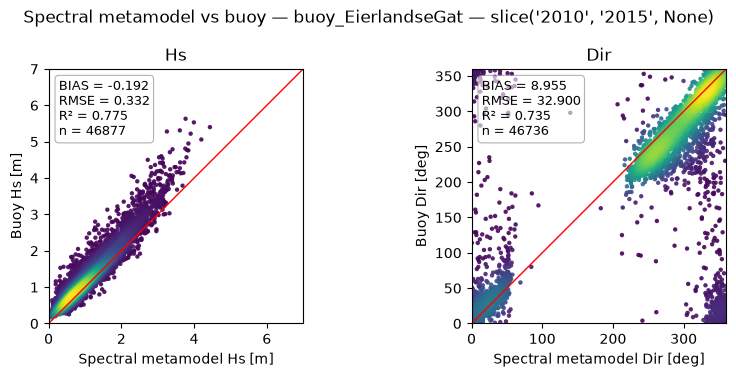

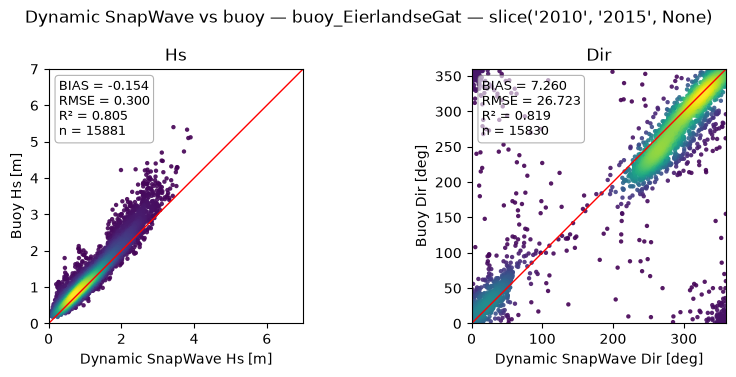

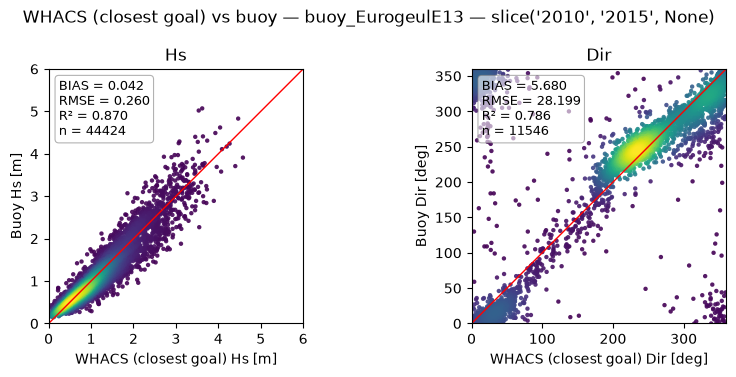

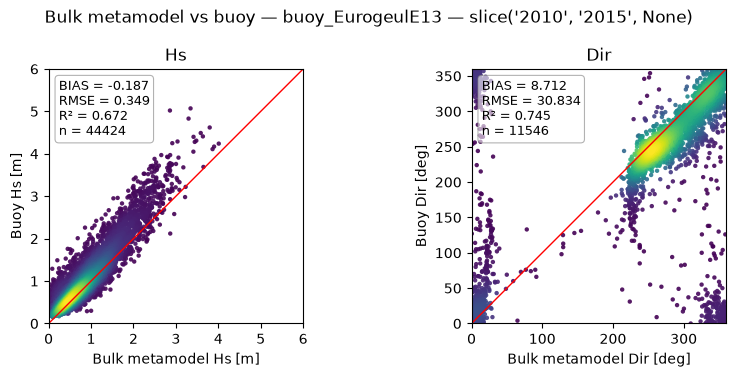

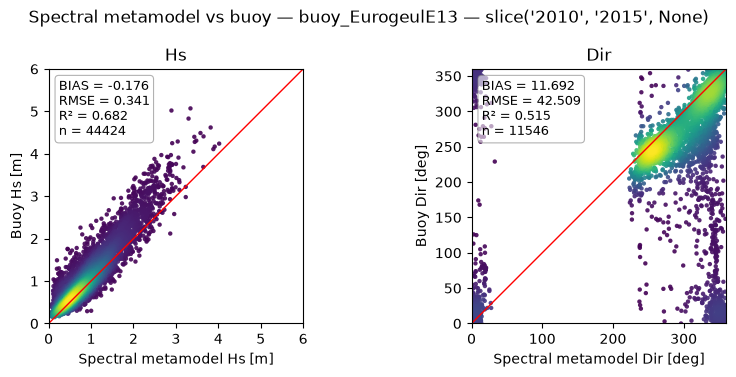

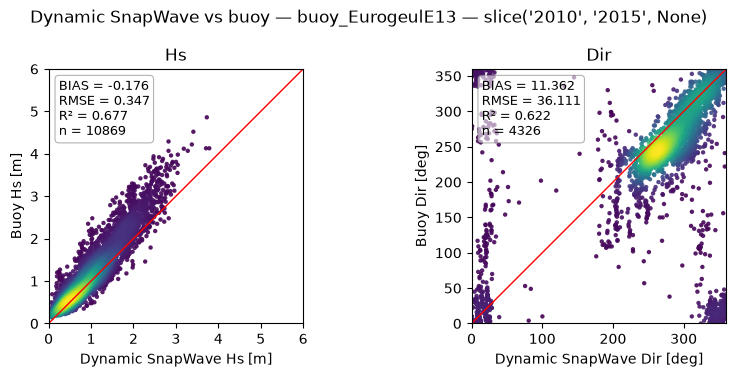

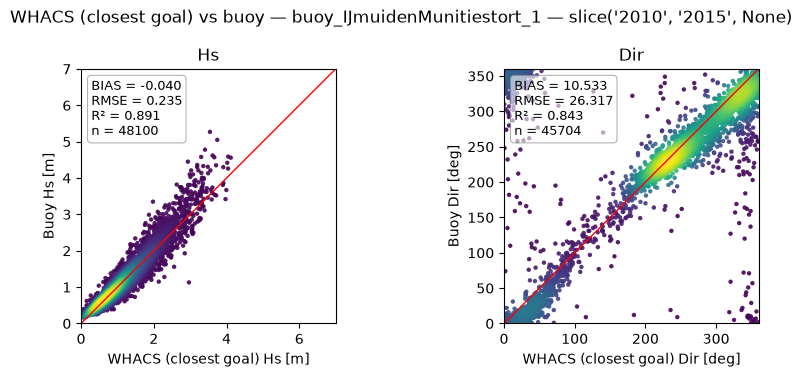

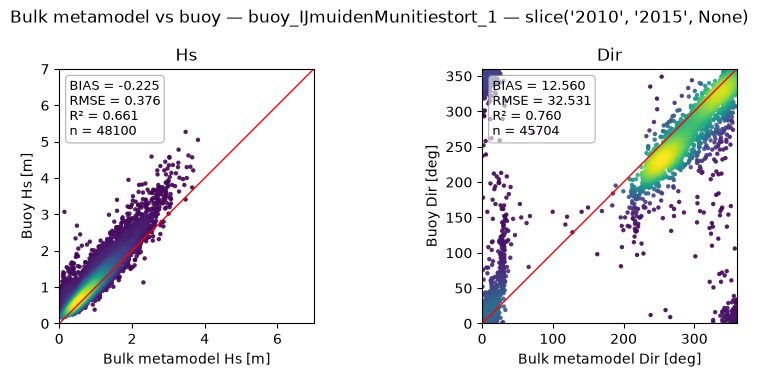

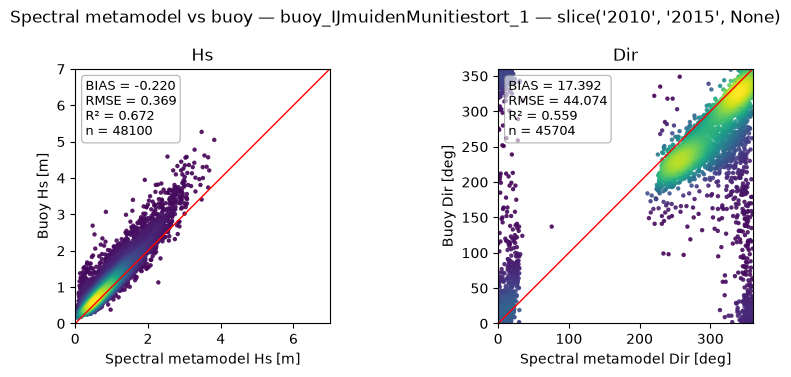

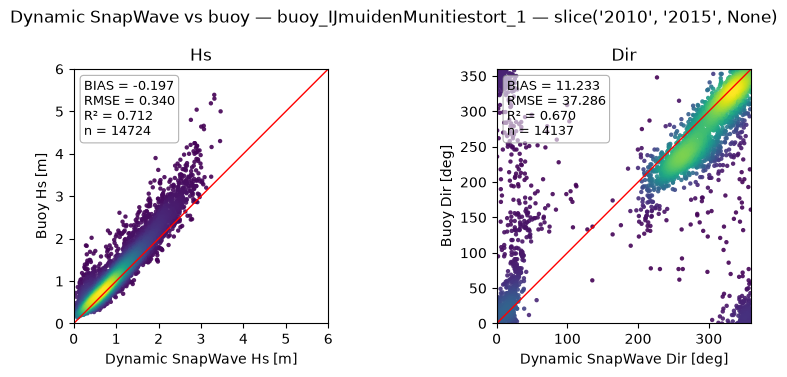

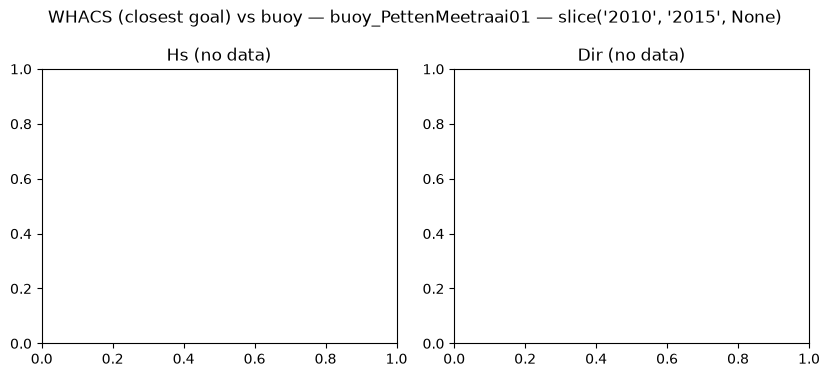

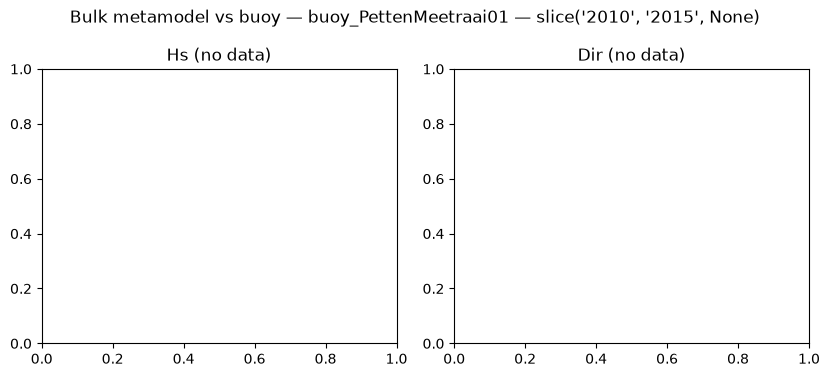

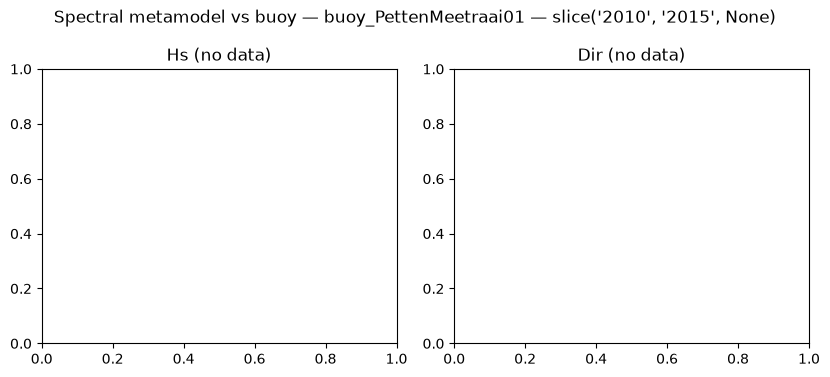

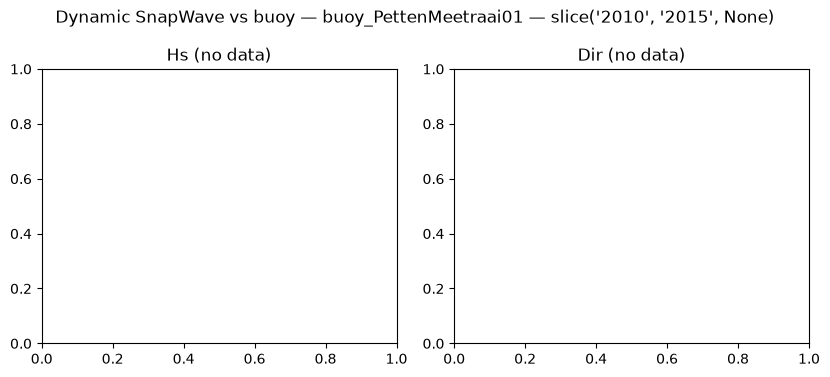

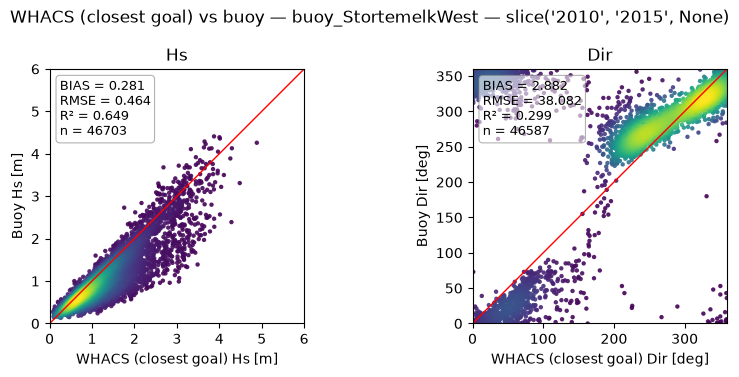

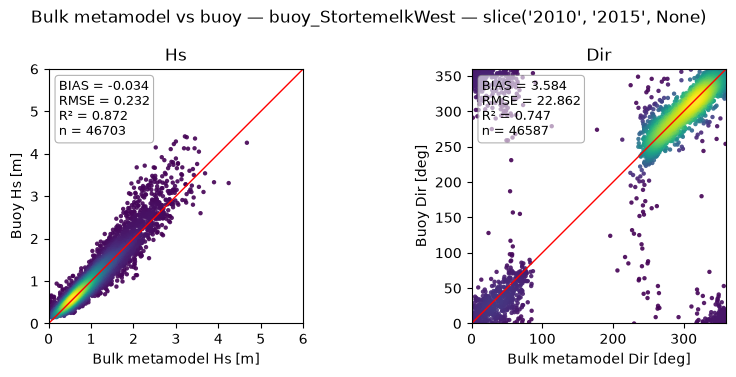

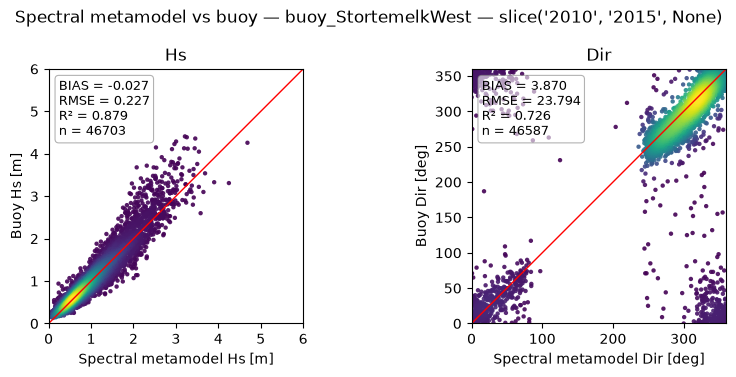

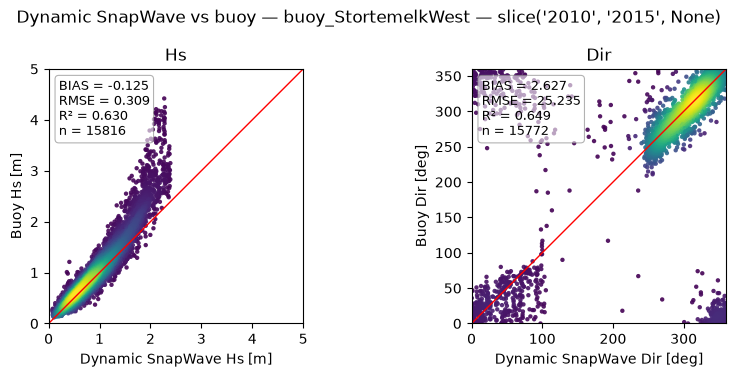

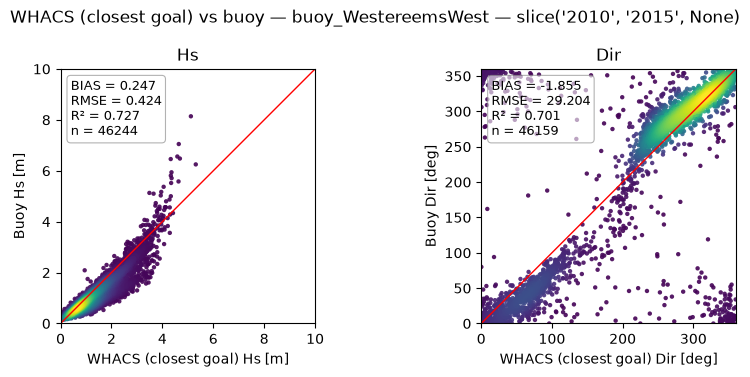

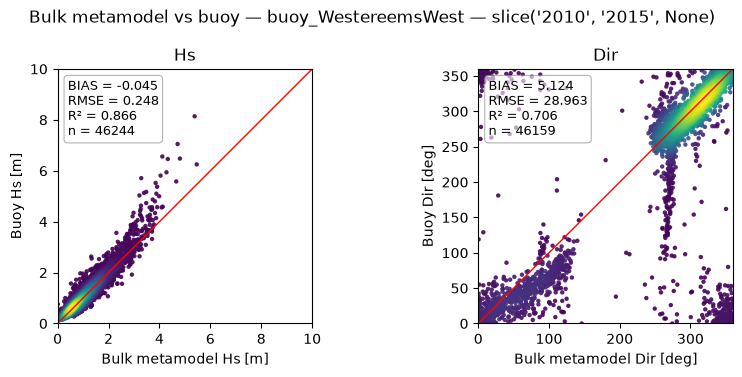

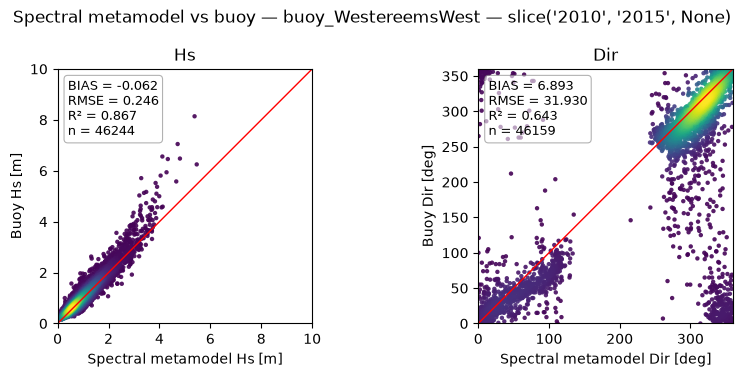

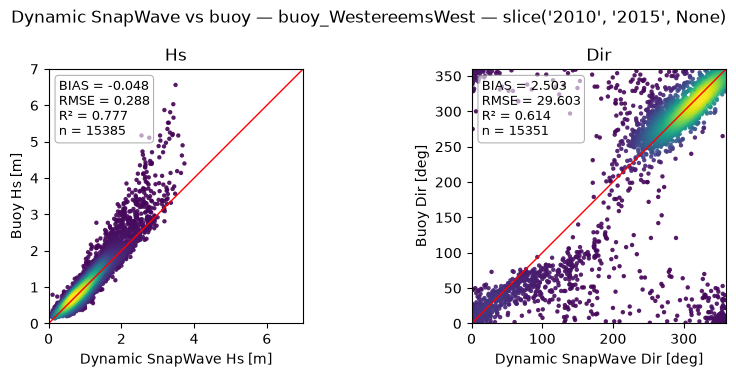

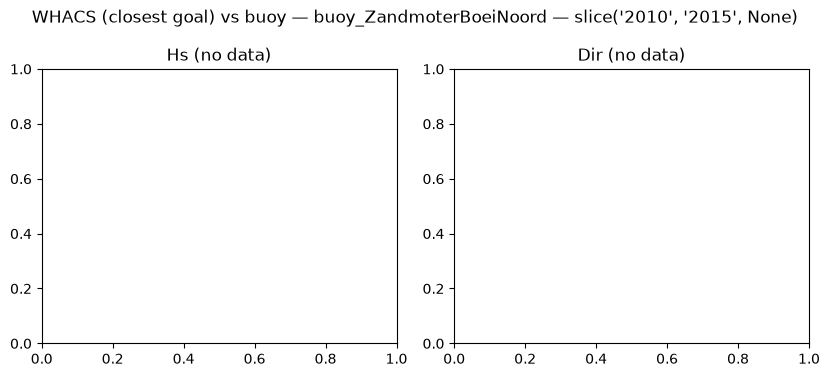

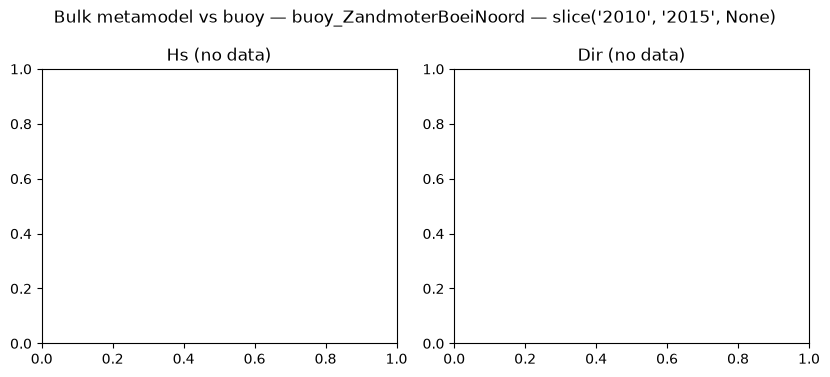

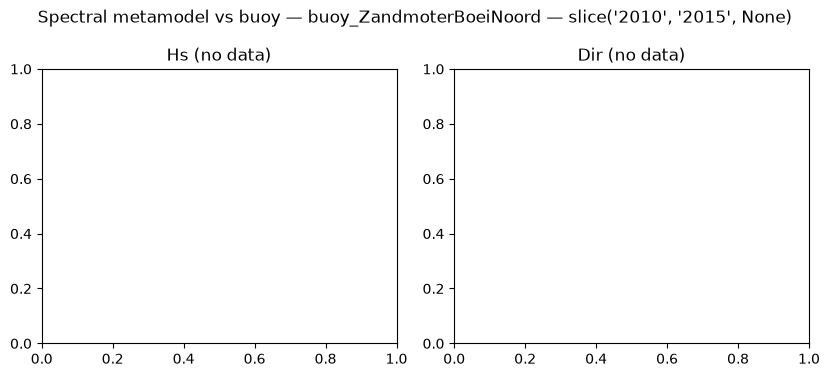

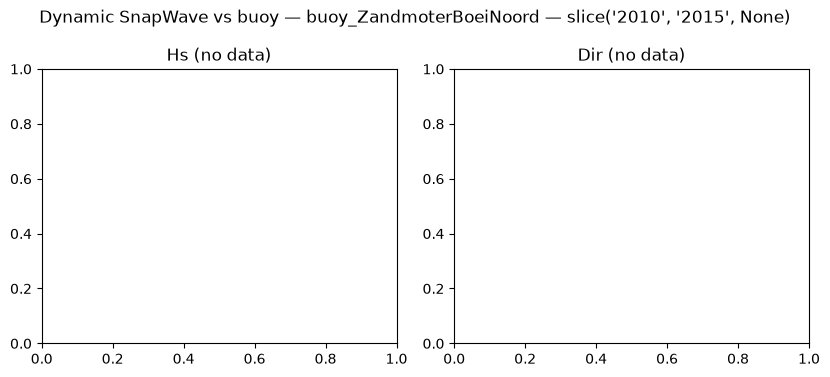

In [10]:
for site in sites:
    for name, result in results.items():
        result.plot_scatter(
            site,
            variables=variables,
            estimate_label=name,
            reference_label="Buoy",
        )
        plt.suptitle(f"{name} vs buoy — {site} — {period}")
        plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

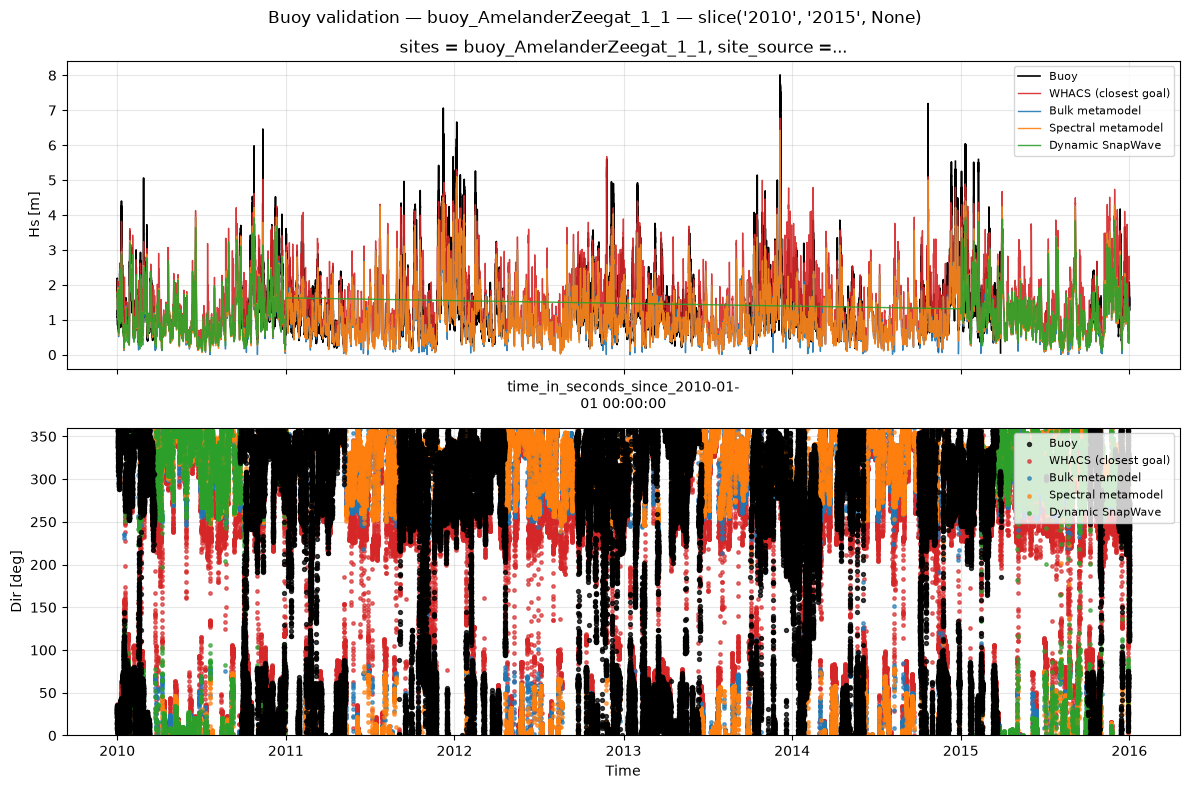

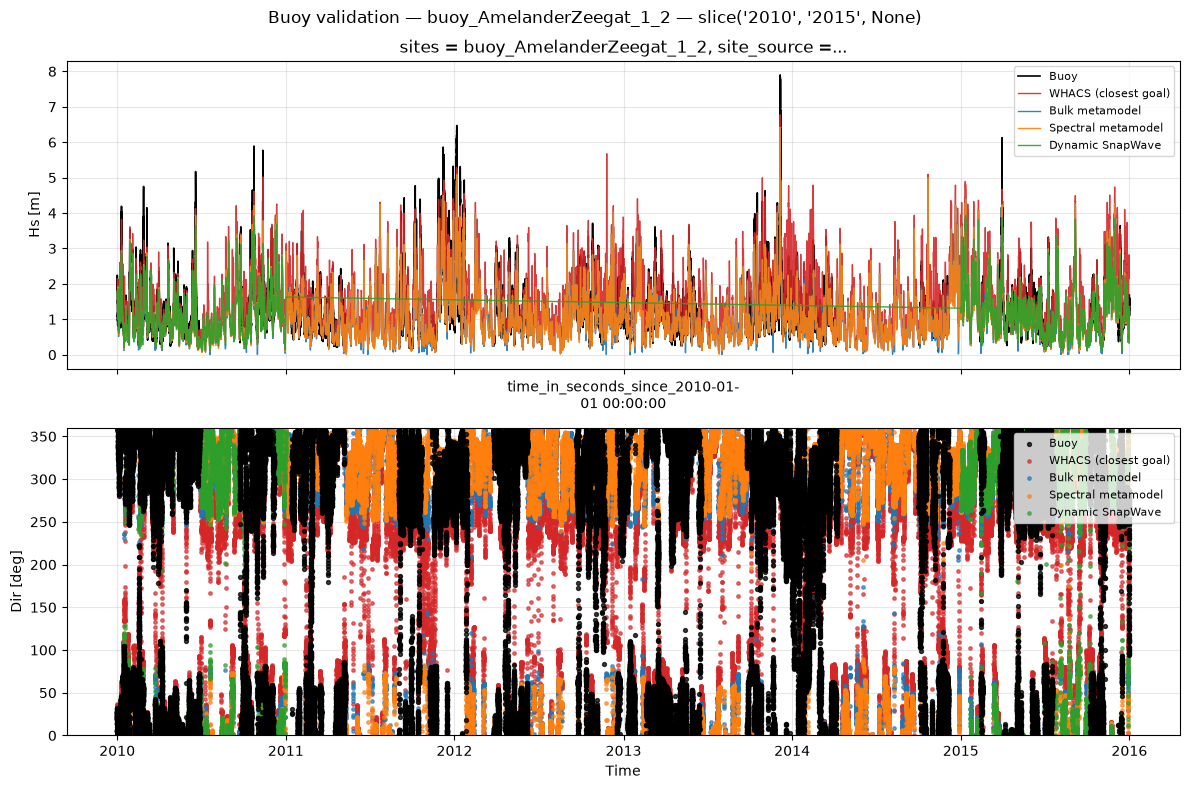

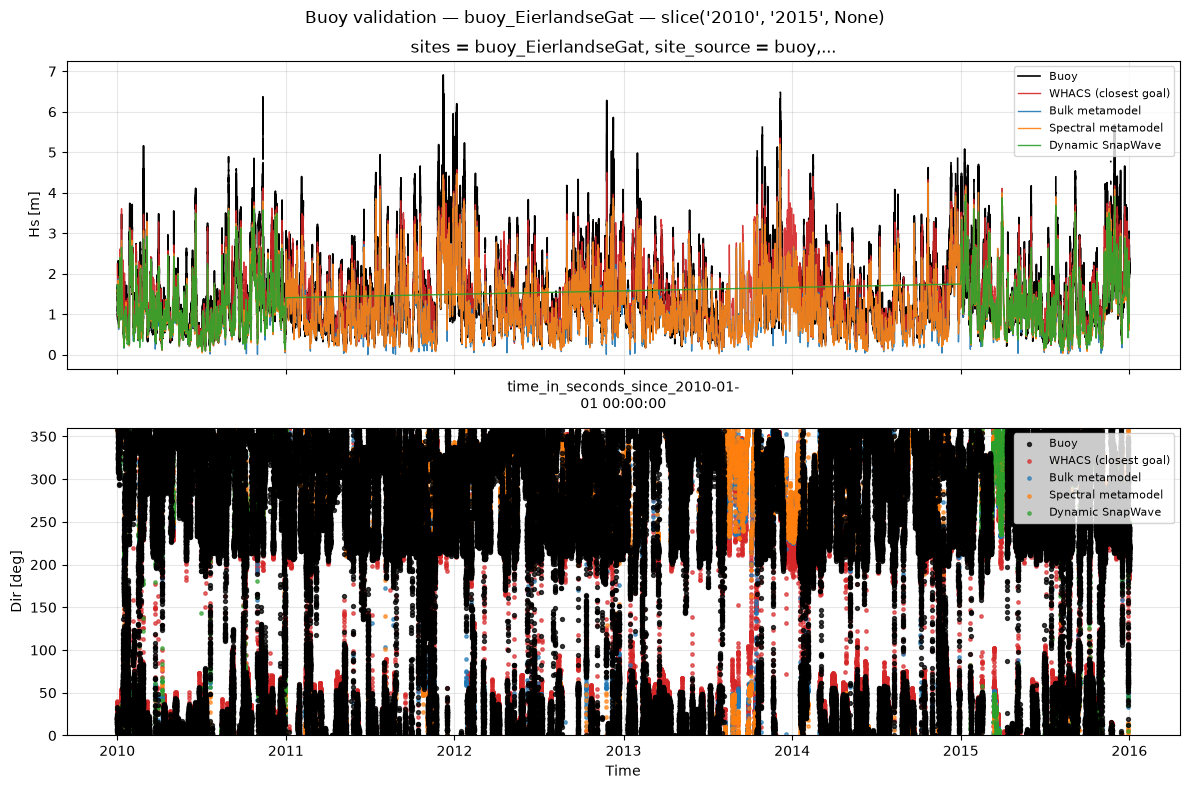

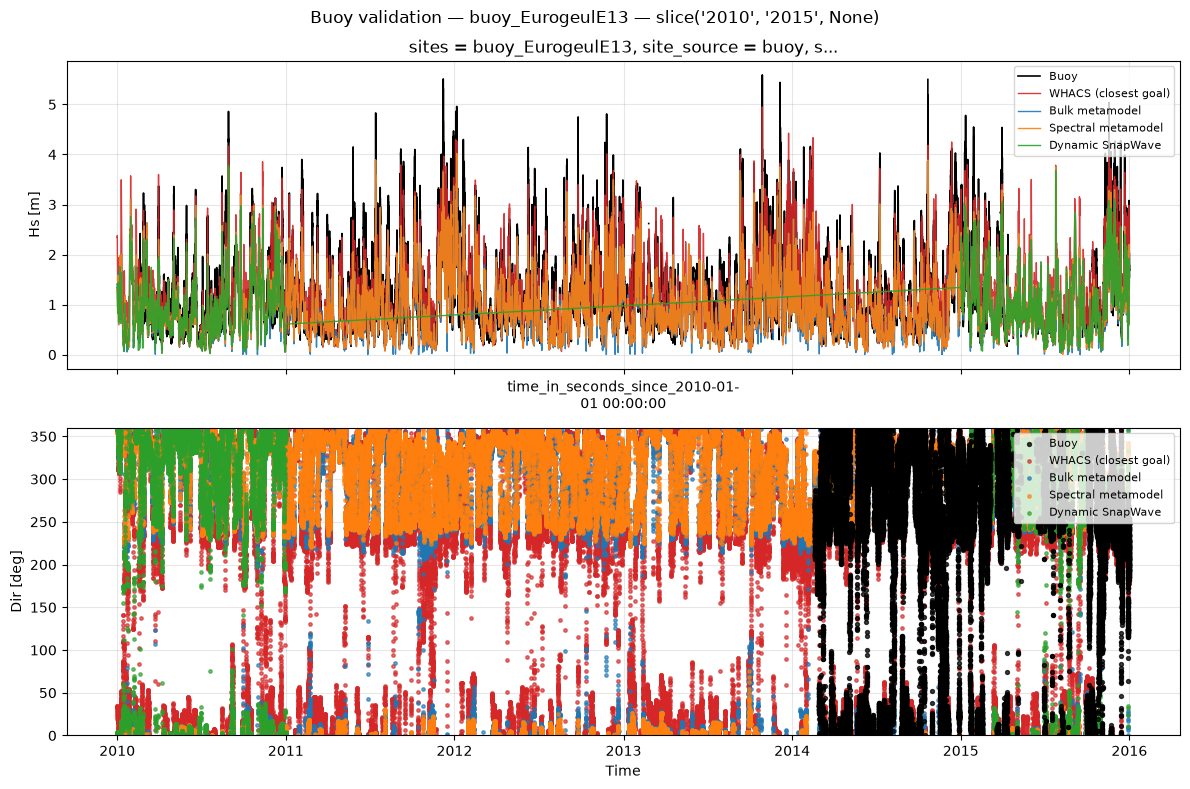

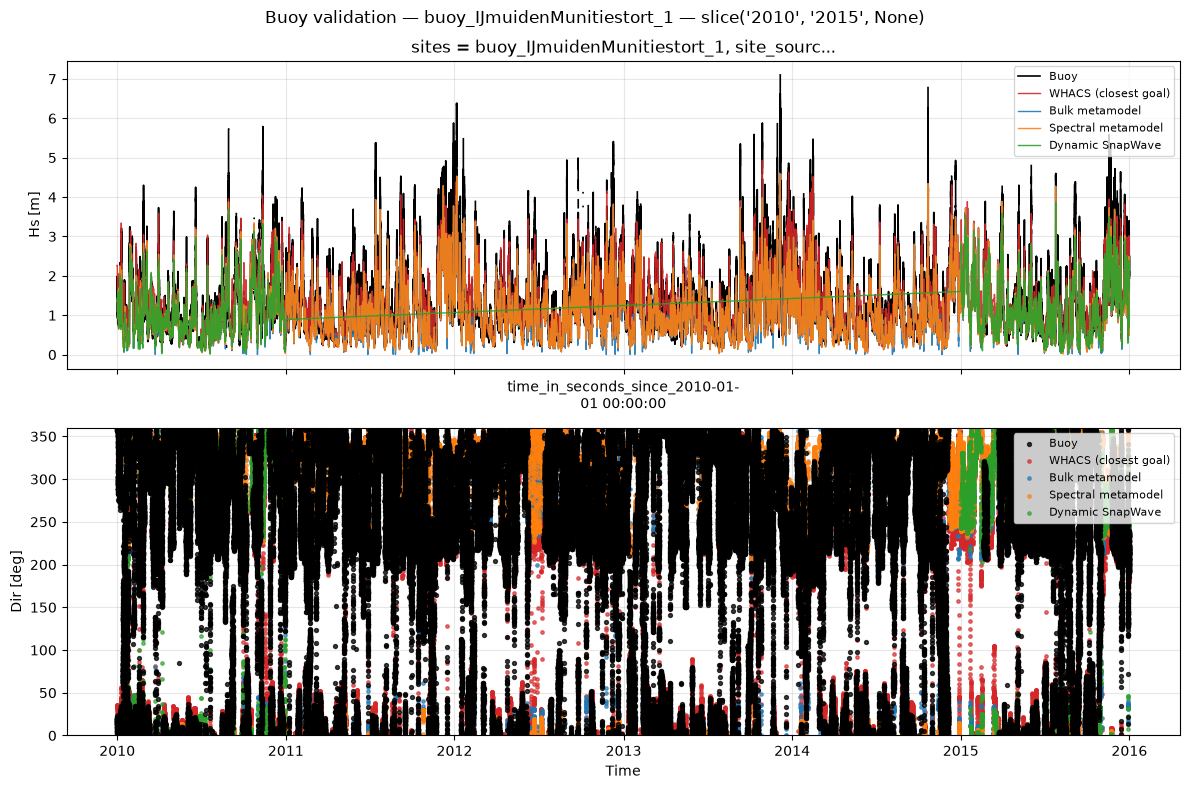

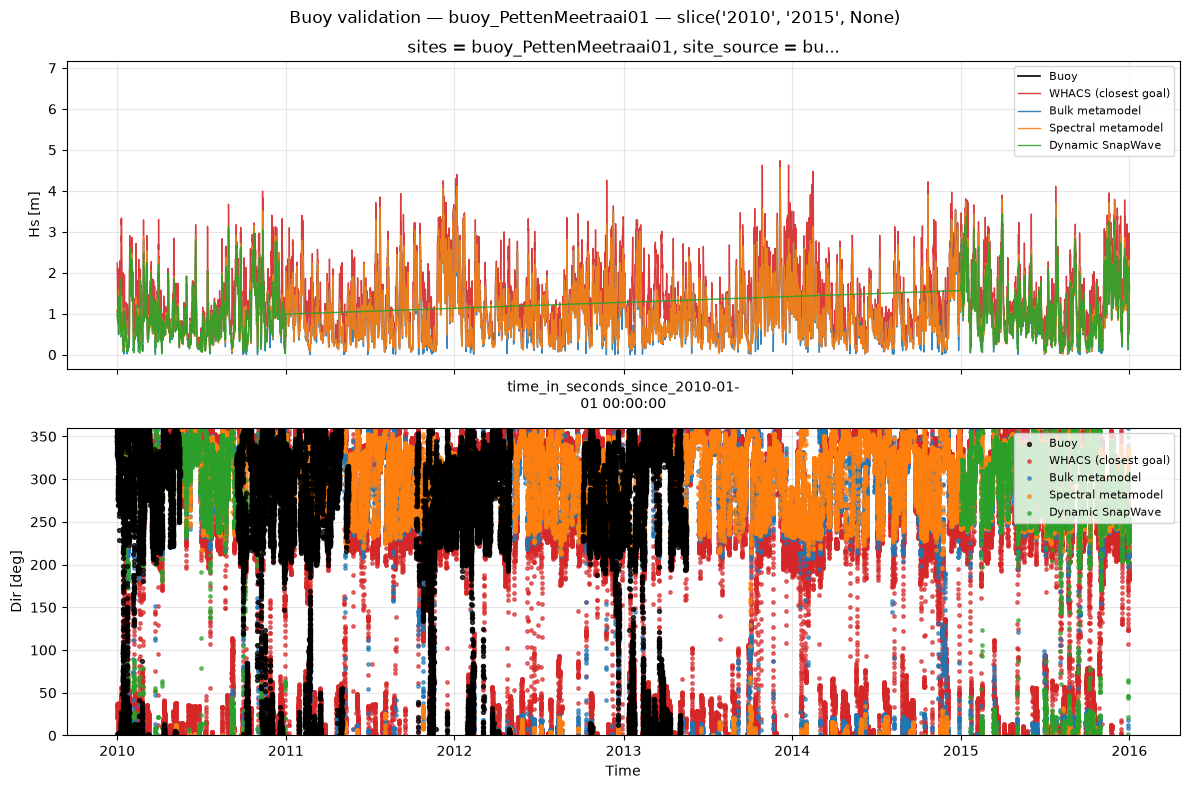

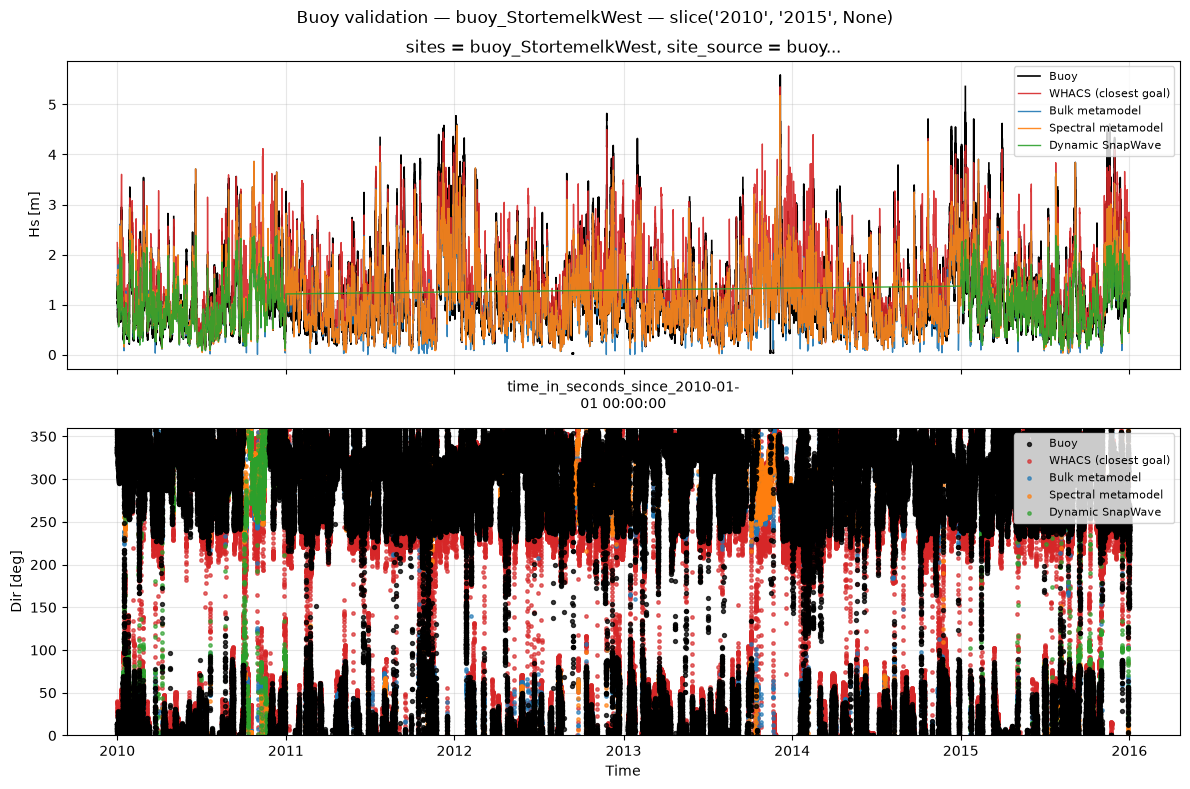

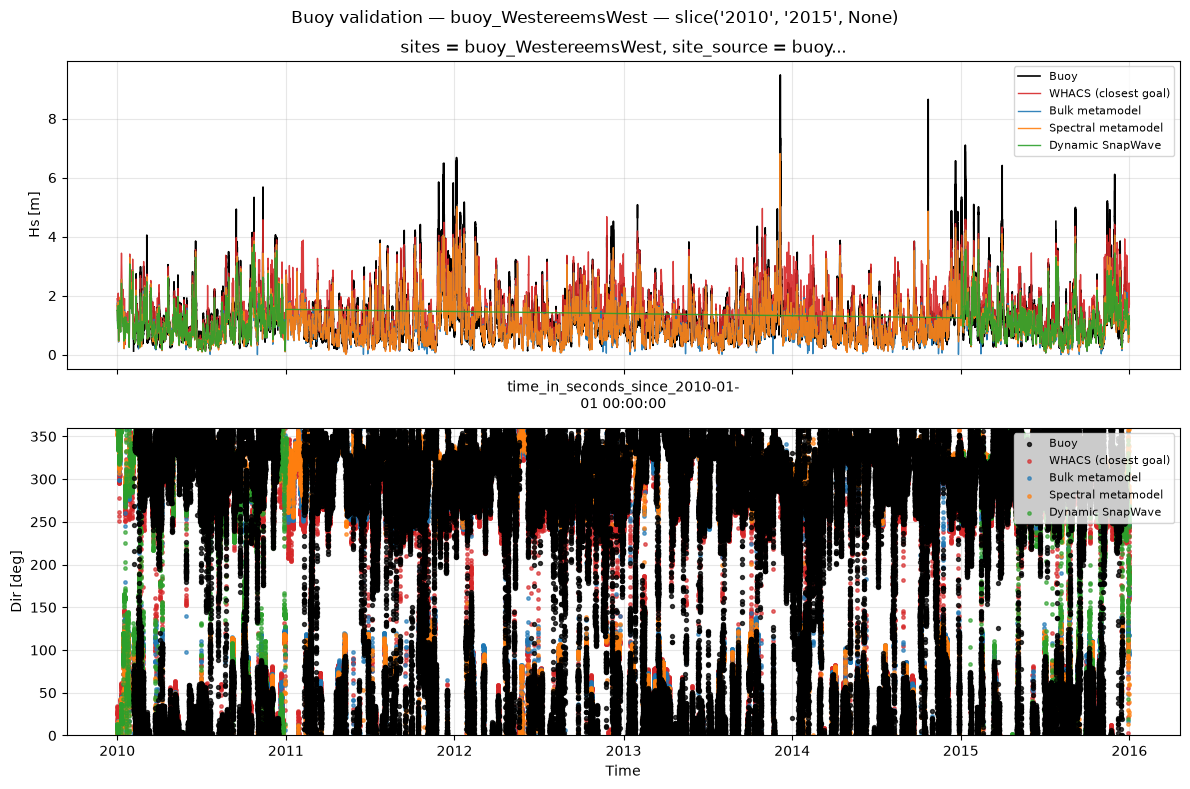

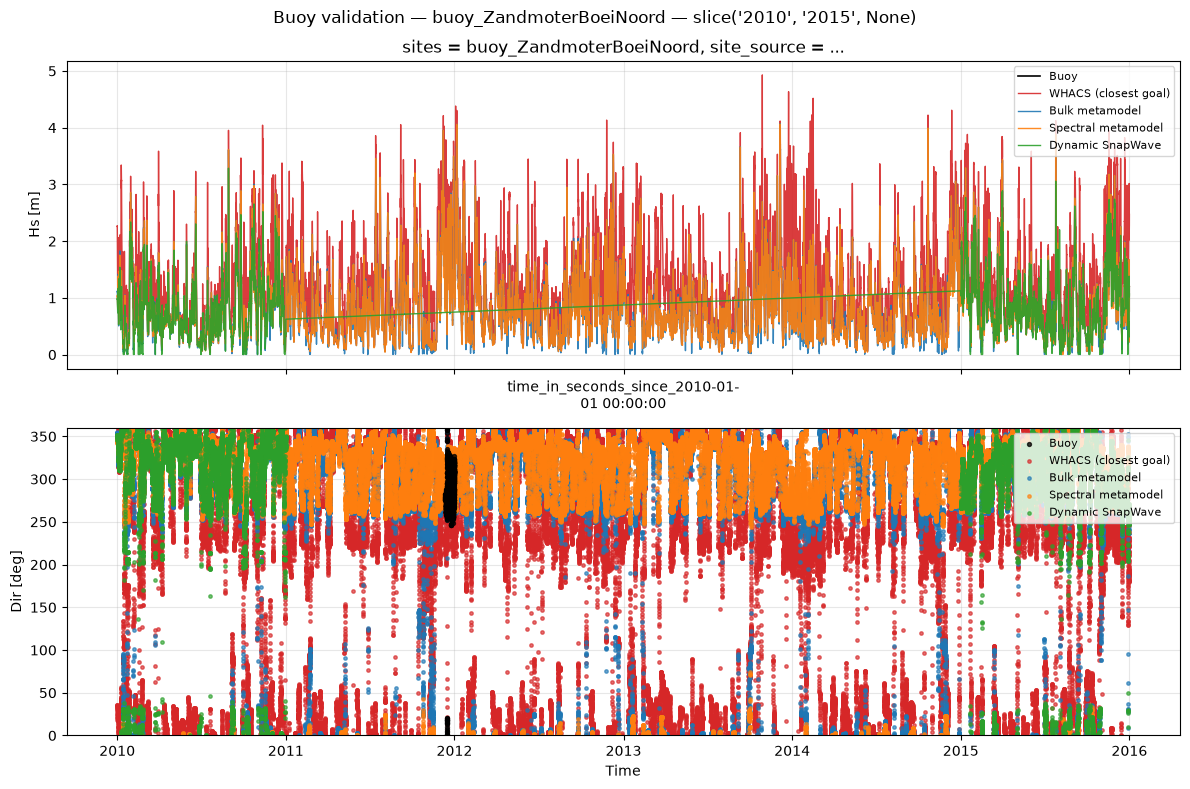

In [11]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()

## 7 · Save per-buoy summary PNG (GUI)

Density scatter (top row, buoy vs. spectral metamodel) + one wide Hs/Tp time series (bottom row, cropped to when the buoy actually has data) — one combined PNG per buoy, shown as-is in the GUI's Buoy Validation tab when you click that buoy's star on the map.

In [12]:
for site in sites:
    fig = val.plot_buoy_summary(
        buoy,
        estimates,
        site,
        variables=variables,
        reference_label="Buoy",
        period_label=period_label,
    )
    out_path = val.buoy_summary_figure_path(site)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"saved {out_path}")

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AmelanderZeegat_1_1.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AmelanderZeegat_1_2.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_EierlandseGat.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_EurogeulE13.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_IJmuidenMunitiestort_1.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_PettenMeetraai01.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_StortemelkWest.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_WestereemsWest.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_ZandmoterBoeiNoord.png
